In [1]:
print("UrbanFlow begins")

UrbanFlow begins


In [13]:
from importlib.metadata import version

print("Pandas:", version("pandas"))
print("PyTables:", version("tables"))
# both must be compatible


Pandas: 2.2.3
PyTables: 3.11.1


In [ ]:
import pandas as pd
data=pd.read_hdf("../data/metr-la.h5")
print(data.head())
print(data.shape)
# loading dataset into pandas dataframe

                        773869     767541     767542     717447     717446  \
2012-03-01 00:00:00  64.375000  67.625000  67.125000  61.500000  66.875000   
2012-03-01 00:05:00  62.666667  68.555556  65.444444  62.444444  64.444444   
2012-03-01 00:10:00  64.000000  63.750000  60.000000  59.000000  66.500000   
2012-03-01 00:15:00   0.000000   0.000000   0.000000   0.000000   0.000000   
2012-03-01 00:20:00   0.000000   0.000000   0.000000   0.000000   0.000000   

                        717445  773062  767620     737529     717816  ...  \
2012-03-01 00:00:00  68.750000  65.125  67.125  59.625000  62.750000  ...   
2012-03-01 00:05:00  68.111111  65.000  65.000  57.444444  63.333333  ...   
2012-03-01 00:10:00  66.250000  64.500  64.250  63.875000  65.375000  ...   
2012-03-01 00:15:00   0.000000   0.000   0.000   0.000000   0.000000  ...   
2012-03-01 00:20:00   0.000000   0.000   0.000   0.000000   0.000000  ...   

                        772167  769372     774204     769806  717590

In [15]:
print("Index type:", type(data.index))
print("Index dtype:", data.index.dtype)
print("First timestamp values:", repr(data.index.values[:5]))

Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Index dtype: datetime64[ns]
First timestamp values: array(['2012-03-01T00:00:00.000000000', '2012-03-01T00:05:00.000000000',
       '2012-03-01T00:10:00.000000000', '2012-03-01T00:15:00.000000000',
       '2012-03-01T00:20:00.000000000'], dtype='datetime64[ns]')


In [18]:
data.index = pd.DatetimeIndex(data.index.values)

print(data.index[:5])
print(data.index[-5:])
#data.index.values extracts the actual timestamps.
#pd.DatetimeIndex() creates a fresh datetime index. we are doing this because 
 # loading hd5 file into pd dataframe can break the frequency metadata
#data.index = assigns that fresh index back to our DataFrame.


DatetimeIndex(['2012-03-01 00:00:00', '2012-03-01 00:05:00',
               '2012-03-01 00:10:00', '2012-03-01 00:15:00',
               '2012-03-01 00:20:00'],
              dtype='datetime64[ns]', freq=None)
DatetimeIndex(['2012-06-27 23:35:00', '2012-06-27 23:40:00',
               '2012-06-27 23:45:00', '2012-06-27 23:50:00',
               '2012-06-27 23:55:00'],
              dtype='datetime64[ns]', freq=None)


In [ ]:
print(data.index[1]-data.index[0])  #sampling interval
print(data.index.min()) #first observation taken
print(data.index.max()) #last observation taken

0 days 00:05:00
2012-03-01 00:00:00
2012-06-27 23:55:00


In [30]:
print(data.isna().sum().sum()) #sum of missing entries across all rows and columns
print((data==0).sum().sum()) #total zero values
print((data==0).sum().head(10)) #zeros per column(sensor id)
print((data==0).sum().idxmax());print((data==0).sum().max())

zero_cnt_per_sensor=(data==0).sum()
zero_percentage=((zero_cnt_per_sensor)/len(data))*100
zero_percentage.describe()

0
575302
773869    3843
767541    2149
767542    2149
717447    2174
717446    2463
717445    2183
773062    2176
767620    3257
737529    2684
717816    2313
dtype: int64
718076
6890


count    207.000000
mean       8.109351
std        2.446335
min        6.267507
25%        6.379844
50%        6.973623
75%        9.035072
max       20.103875
dtype: float64

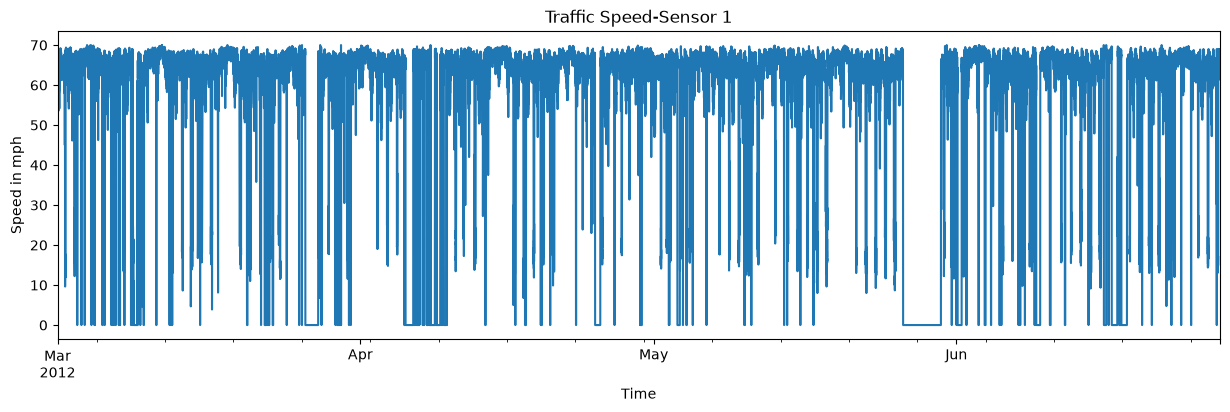

In [31]:
import matplotlib.pyplot as plt
data.iloc[:,0].plot(figsize=(15,4)) #data.iloc[row,col] , : selects all rows
plt.title("Traffic Speed-Sensor 1")
plt.xlabel("Time")
plt.ylabel("Speed in mph")
plt.show()

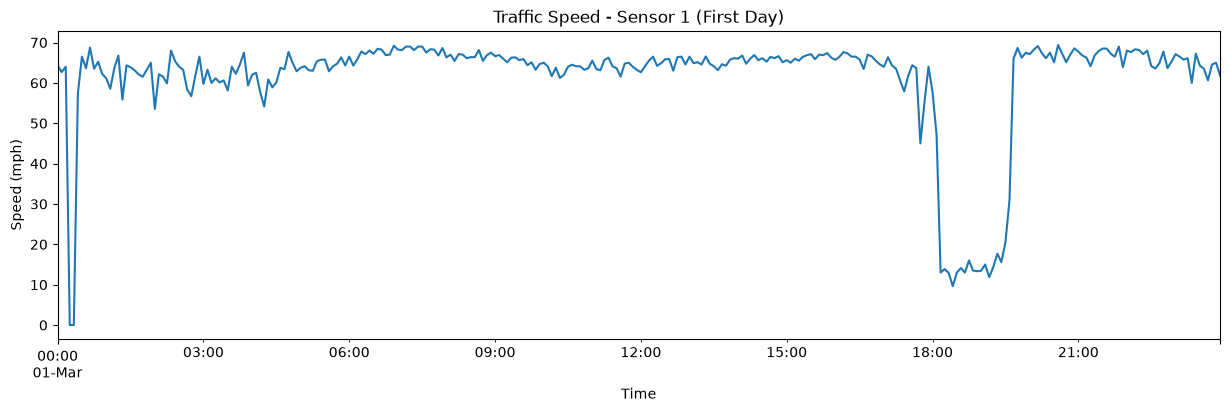

In [34]:
data.iloc[:288, 0].plot(figsize=(15, 4))  #12*24=288
plt.title("Traffic Speed - Sensor 1 (First Day)")
plt.xlabel("Time")
plt.ylabel("Speed (mph)")
plt.show()

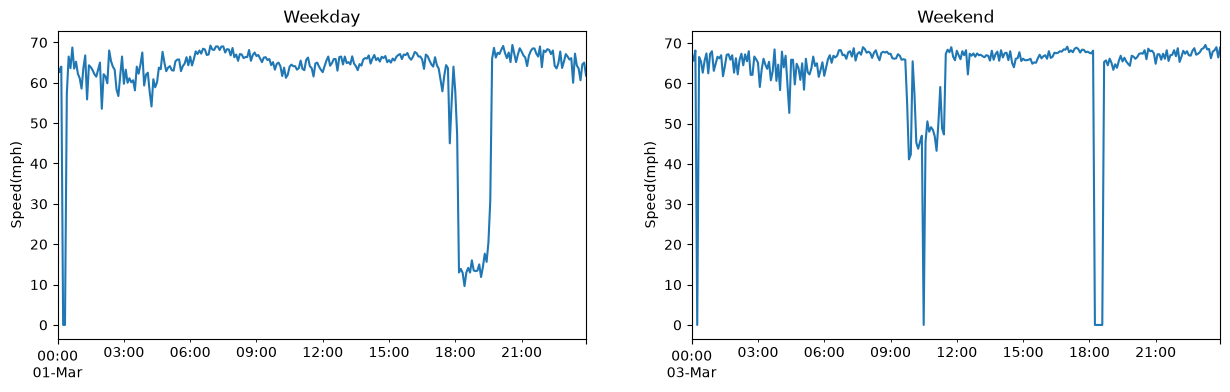

In [41]:
weekday=data.loc["2012-03-01"]
weekend=data.loc["2012-03-03"]

fig,axes=plt.subplots(1,2,figsize=(15,4))
weekday.iloc[:,0].plot(ax=axes[0]);axes[0].set_title("Weekday");axes[0].set_ylabel("Speed(mph)")
weekend.iloc[:,0].plot(ax=axes[1]);axes[1].set_title("Weekend");axes[1].set_ylabel("Speed(mph)")
#plt.tight_layout()
plt.show()

In [43]:
hourly_average=data.groupby(data.index.hour).mean().mean(axis=1)
print(hourly_average)

0     56.321629
1     56.686634
2     55.079091
3     53.947426
4     55.014033
5     56.525704
6     54.735278
7     50.885707
8     48.602117
9     50.500531
10    52.363103
11    54.168524
12    53.490242
13    52.636549
14    51.779164
15    50.122288
16    48.296004
17    46.534521
18    48.991486
19    56.012438
20    59.828343
21    59.139055
22    58.723743
23    58.872898
dtype: float64


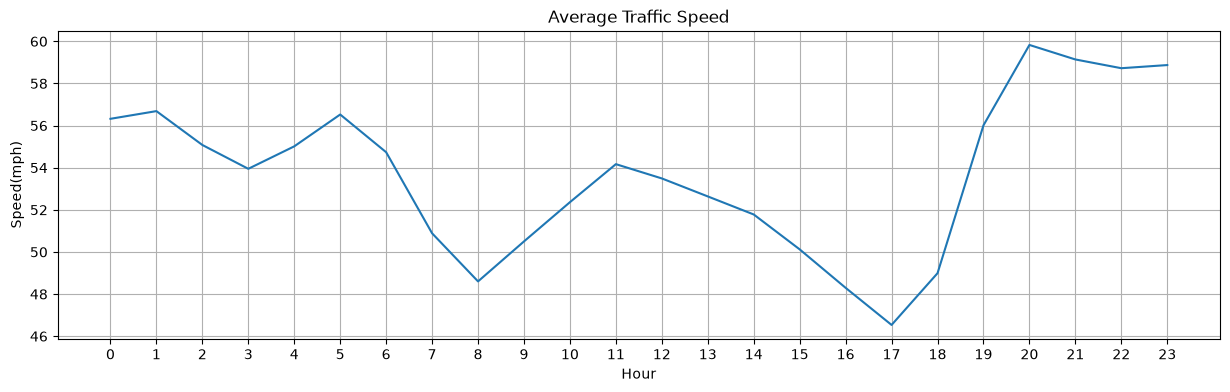

In [49]:
hourly_average.plot(figsize=(15,4))
plt.title("Average Traffic Speed")
plt.xlabel("Hour");plt.ylabel("Speed(mph)")
plt.xticks(range(24));plt.grid(True)
plt.show()

In [50]:
total = len(data)

train_size = int(total * 0.70)
val_size = int(total * 0.10)
test_size = total - train_size - val_size

print("Train:", train_size)
print("Validation:", val_size)
print("Test:", test_size)

Train: 23990
Validation: 3427
Test: 6855


In [51]:
train_data = data.iloc[:train_size]
val_data = data.iloc[train_size:train_size + val_size]
test_data = data.iloc[train_size + val_size:]

print(train_data.shape)
print(val_data.shape)
print(test_data.shape)

(23990, 207)
(3427, 207)
(6855, 207)


In [52]:
print("Training:", train_data.index[0], "to", train_data.index[-1])
print("Validation:", val_data.index[0], "to", val_data.index[-1])
print("Testing:", test_data.index[0], "to", test_data.index[-1])

Training: 2012-03-01 00:00:00 to 2012-05-23 07:05:00
Validation: 2012-05-23 07:10:00 to 2012-06-04 04:40:00
Testing: 2012-06-04 04:45:00 to 2012-06-27 23:55:00
